# Replication of Cluster: Discovery ↔ Validation

1. For each cluster and each common variable, calculate the **distribution of responses** (weighted proportions per category).
2. For each pair of D- and V-clusters, compare how similar these distributions are (**Total Variation Distance**).
3. Assign the most similar V-cluster to each D-cluster.

## Step 0: Load Data
Imputed data, survey weights `wichtn`, GMM labels.

In [2]:
import ast
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

project_path = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
os.chdir(project_path)
sys.path.insert(0, str(project_path))

from utils.saving_utils import DatasetBundle

output_folder = Path("outputs/cluster_replication")
output_folder.mkdir(parents=True, exist_ok=True)

data_discov = DatasetBundle.load(Path("data/imputed/data_discov_imputed"))
data_valid = DatasetBundle.load(Path("data/imputed/data_valid_imputed"))
D_raw = data_discov.data.reset_index(drop=True)
V_raw = data_valid.data.reset_index(drop=True)

w_D = pd.to_numeric(DatasetBundle.load(Path("data/preprocessed/data_discov_full")).data["wichtn"]).to_numpy(dtype=float)
w_V = pd.to_numeric(DatasetBundle.load(Path("data/preprocessed/data_valid_full")).data["wichtn"]).to_numpy(dtype=float)

lab_D = pd.read_parquet("outputs/gmm_clustering/cluster_pred_discov.parquet")["label"].astype(str).to_numpy()
lab_V = pd.read_parquet("outputs/gmm_clustering/cluster_pred_valid.parquet")["label"].astype(str).to_numpy()

def sort_clusters(cs):
    return sorted(cs, key=lambda c: int(c) if str(c).isdigit() else str(c))

def sizes(labels, w):
    s = pd.DataFrame({"n": pd.Series(labels).value_counts(),
                      "anteil_gew": pd.Series(w).groupby(labels).sum() / w.sum()})
    return s.loc[sort_clusters(s.index)]

size_D, size_V = sizes(lab_D, w_D), sizes(lab_V, w_V)

Loaded dataset from data/imputed/data_discov_imputed.
Loaded dataset from data/imputed/data_valid_imputed.
Loaded dataset from data/preprocessed/data_discov_full.
Loaded dataset from data/preprocessed/data_valid_full.


## Step 1: Common Variables and Their Distributions
- Only variables that are measured in **both** samples are used. The remaining variables are listed.
- Binary, nominal, and ordinal variables remain as they are: Each category is assigned its proportion. Value labels from the metadata (e.g., *yes/no*) are adopted.
- Continuous variables are divided into classes: **0** and three equally sized groups of values > 0 (boundaries determined jointly from both samples).
- Proportions are **weighted** and refer to **individuals with valid responses**.

In [3]:
EXCLUDE = ["wichtn", "lfd", "fall"]

meta = data_discov.meta.set_index("name")
vtype = meta["type"]

shared = [v for v in meta.index if v not in EXCLUDE and v in D_raw.columns and v in V_raw.columns]
not_shared = sorted((set(D_raw.columns) ^ set(V_raw.columns)) - set(EXCLUDE))

print(f"{len(shared)} Variablen in beiden Datensätzen, {len(not_shared)} nur in einem:")
print(not_shared)

def value_labels(v):
    """Wertelabels aus den Metadaten (falls vorhanden), z. B. {0: 'nein', 1: 'ja'}."""
    if "labels" in meta.columns and isinstance(meta.at[v, "labels"], str):
        try:
            return {str(k): str(lab) for k, lab in ast.literal_eval(meta.at[v, "labels"]).items()}
        except (ValueError, SyntaxError):
            pass
    return {}

def categorize(v):
    """Beide Datensätze in dieselben Kategorien überführen (als Text)."""
    if vtype[v] == "continuous":
        xd, xv = pd.to_numeric(D_raw[v], errors="coerce"), pd.to_numeric(V_raw[v], errors="coerce")
        pos = pd.concat([xd, xv])
        pos = pos[pos > 0]
        if pos.nunique() < 3:
            cuts = [0, np.inf]
        else:
            q1, q2 = np.quantile(pos, [1 / 3, 2 / 3])
            cuts = [0, q1, q2, np.inf]
        names = ["0"] + [f"{a:.4g}–{b:.4g}" if np.isfinite(b) else f">{a:.4g}" for a, b in zip(cuts[:-1], cuts[1:])]
        def cut(x):
            out = pd.Series(pd.NA, index=x.index, dtype="string")
            out[x == 0] = "0"
            for name, a, b in zip(names[1:], cuts[:-1], cuts[1:]):
                out[(x > a) & (x <= b)] = name
            return out
        return cut(xd), cut(xv)
    labels = value_labels(v)
    conv = lambda s: s.astype("string").map(lambda c: labels.get(c, c) if pd.notna(c) else pd.NA)
    return conv(D_raw[v]), conv(V_raw[v])

cats = {v: categorize(v) for v in shared}

def distributions(series, labels, w):
    """Gewichtete Anteile je Kategorie und Cluster."""
    ok = series.notna().to_numpy()
    df = pd.DataFrame({"cat": series[ok].to_numpy(), "cl": labels[ok], "w": w[ok]})
    tab = df.pivot_table(index="cl", columns="cat", values="w", aggfunc="sum", fill_value=0)
    total = df.groupby("cat")["w"].sum()
    return tab.div(tab.sum(axis=1), axis=0), total / total.sum()

dist = {}
for v, (sd, sv) in cats.items():
    pD, totD = distributions(sd, lab_D, w_D)
    pV, totV = distributions(sv, lab_V, w_V)
    allcats = pD.columns.union(pV.columns)
    dist[v] = (pD.reindex(columns=allcats, fill_value=0), pV.reindex(columns=allcats, fill_value=0),
               totD.reindex(allcats, fill_value=0))

38 Variablen in beiden Datensätzen, 24 nur in einem:
['audit', 'dsm_au', 'dsm_au_m', 'dsm_ber', 'dsm_ber_m', 'dsm_ha', 'dsm_ha_m', 'dsm_kc', 'dsm_kc_m', 'dsm_schl', 'dsm_schl_m', 'dsm_ta', 'fag_sch', 'fr12_meth1', 'harmf', 'hazar', 'hnb_fag_sch', 'pomi', 'psecdi_sch', 'rist', 'rist_noa', 'sds_a', 'sds_c', 'sds_k']


## Step 2: Distance Between Clusters and Assignment

**Total Variation Distance (TVD)** for a variable:

TVD = ½ · Σ |Proportion in Cluster D − Proportion in Cluster V| (across all categories)

→ The proportion of people who would have to switch categories for both distributions to be equal. **0 = identical, 1 = no overlap at all.**

The distance between a pair of clusters is the **mean of the TVD across all shared variables** (each variable counts once).

In the table:
- `best_V` / `TVD`: the most similar validation cluster and its distance
- `second_best_V` / `TVD_2`: for comparison. Large difference between `TVD` and `TVD_2` = unambiguous assignment
- `reciprocal`: Is the D-cluster, in turn, also the most similar to this V-cluster? `True` = strongest form of replication

Additionally: Validation clusters that are not the best counterpart for any D-cluster (= types that exist only in the validation set).

In [4]:
cl_D, cl_V = list(size_D.index), list(size_V.index)
tvd = {}   # tvd[v] = DataFrame D x V
for v, (pD, pV, _) in dist.items():
    m = pd.DataFrame(index=cl_D, columns=cl_V, dtype=float)
    for d in cl_D:
        for c in cl_V:
            if d in pD.index and c in pV.index:
                m.loc[d, c] = 0.5 * np.abs(pD.loc[d] - pV.loc[c]).sum()
    tvd[v] = m

tvd_mean = sum(m.fillna(0) for m in tvd.values()) / sum(m.notna().astype(int) for m in tvd.values())
tvd_mean.to_csv(output_folder / "tvd_mittel_D_x_V.csv")

best_V = tvd_mean.idxmin(axis=1)
best_D = tvd_mean.idxmin(axis=0)

rows = []
for d in cl_D:
    r = tvd_mean.loc[d].sort_values()
    rows.append({
        "D": d, "n_D": size_D.at[d, "n"], "anteil_D": size_D.at[d, "anteil_gew"],
        "bestes_V": r.index[0], "n_V": size_V.at[r.index[0], "n"], "TVD": r.iloc[0],
        "zweitbestes_V": r.index[1], "TVD_2": r.iloc[1],
        "gegenseitig": best_D[r.index[0]] == d,   # ist D auch für dieses V das beste Gegenstück?
    })
matching = pd.DataFrame(rows).set_index("D").sort_values("n_D", ascending=False)

print("Zuordnung Discovery → Validation (mittlere TVD, 0 = identisch):")
display(matching.round(3))

unmatched_V = [c for c in cl_V if c not in set(best_V)]
print("Validation-Cluster, die für kein Discovery-Cluster das beste Gegenstück sind:", unmatched_V)
matching.to_csv(output_folder / "zuordnung_D_V.csv")

Zuordnung Discovery → Validation (mittlere TVD, 0 = identisch):


,n_D,anteil_D,bestes_V,n_V,TVD,zweitbestes_V,TVD_2,gegenseitig
D,,,,,,,,
0,2858,0.300,0,3319,0.023,3,0.082,True
1,1893,0.231,1,1426,0.017,2,0.152,True
2,1226,0.152,0,3319,0.035,3,0.089,False
3,1199,0.128,3,949,0.069,4,0.080,True
4,627,0.075,2,1117,0.022,4,0.097,True
5,335,0.038,5,590,0.044,4,0.073,True
6,273,0.028,6,365,0.051,5,0.100,True
8,190,0.018,5,590,0.096,6,0.097,False
7,170,0.022,2,1117,0.059,4,0.129,False


Validation-Cluster, die für kein Discovery-Cluster das beste Gegenstück sind: ['7', '8', '9', '10']


## Step 3: Visualization
Values = 1 − mean TVD (1 = identical profiles). Rows: Discovery sorted by size. Columns: Validation in the order of assignment, so that good pairs lie on the diagonal.

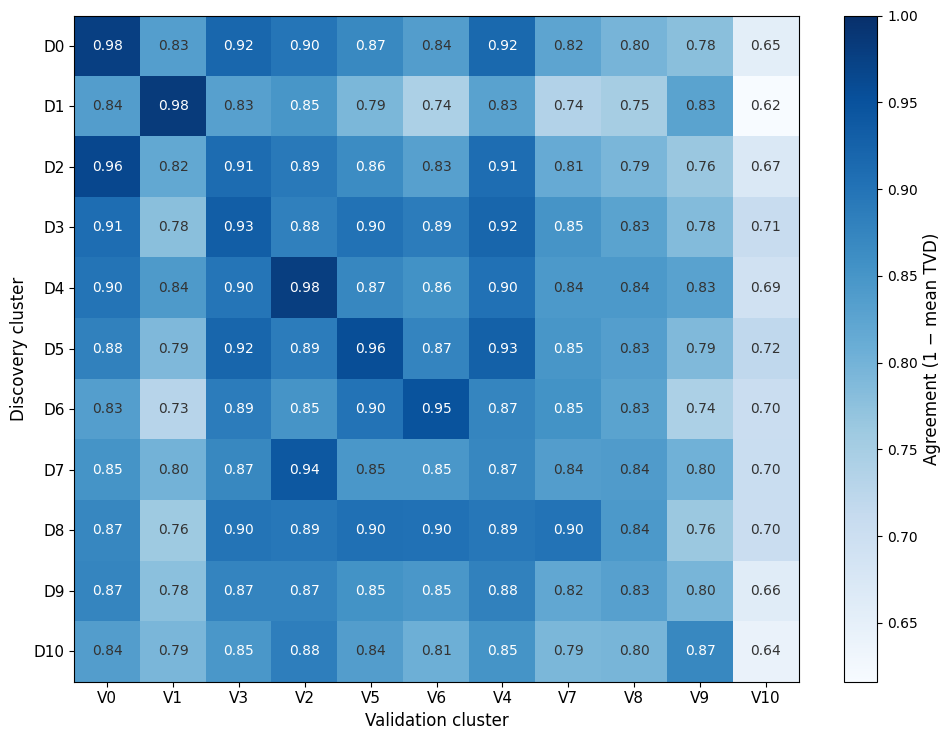

In [ ]:
SHOW_VALUES = True    

rows_order  = cl_D                                                  
matched_V   = list(dict.fromkeys([best_V[d] for d in rows_order]))
unmatched_V = [c for c in cl_V if c not in set(best_V)]
cols_order  = matched_V + unmatched_V
sim = (1 - tvd_mean).loc[rows_order, cols_order]
vmin = sim.min().min()

fig, ax = plt.subplots(figsize=(10, 7.5))
im = ax.imshow(sim.to_numpy(dtype=float), cmap="Blues", vmin=vmin, vmax=1, aspect="auto")


if SHOW_VALUES:
    for i in range(len(rows_order)):
        for j in range(len(cols_order)):
            val = sim.iat[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if val > vmin + 0.6 * (1 - vmin) else "#333333")


ax.set_xticks(range(len(cols_order)))
ax.set_xticklabels([f"V{c}" for c in cols_order], fontsize=11)
ax.set_yticks(range(len(rows_order)))
ax.set_yticklabels([f"D{d}" for d in rows_order], fontsize=11)
ax.set_xlabel("Validation cluster", fontsize=12)
ax.set_ylabel("Discovery cluster", fontsize=12)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Agreement (1 − mean TVD)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()
plt.savefig(output_folder / "agreement_D_V.png", dpi=300, bbox_inches="tight")
plt.show()